## EDA for the files created in step 1 - simulation

### Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Customers File - `customers.csv`

In [2]:
cust_df = pd.read_csv('../data/raw/customers.csv')
cust_df.sample(5)

,customer_id,segment,offer,avg_weekly_hours_pre
275318,275319,Low,Free Trial,1.533559
52948,52949,Low,Discount,3.829244
130217,130218,Low,Free Trial,1.441293
277293,277294,Medium,Early Access,12.228558
102525,102526,Medium,Discount,1.687138


In [3]:
cust_df.describe()

,customer_id,avg_weekly_hours_pre
count,500000.000000,500000.000000
mean,250000.500000,4.782466
std,144337.711634,5.257362
min,1.000000,0.155886
25%,125000.750000,1.619760
50%,250000.500000,2.881887
75%,375000.250000,5.774691
max,500000.000000,104.733726


In [4]:
cust_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 4 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   customer_id           500000 non-null  int64  
 1   segment               500000 non-null  object 
 2   offer                 500000 non-null  object 
 3   avg_weekly_hours_pre  500000 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 15.3+ MB


In [5]:
cust_df['offer'].value_counts()

offer
Free Trial      150001
Early Access    150001
Discount        150000
Control          49998
Name: count, dtype: int64

In [6]:
cust_df['segment'].value_counts()

segment
Low       249555
Medium    175398
High       75047
Name: count, dtype: int64

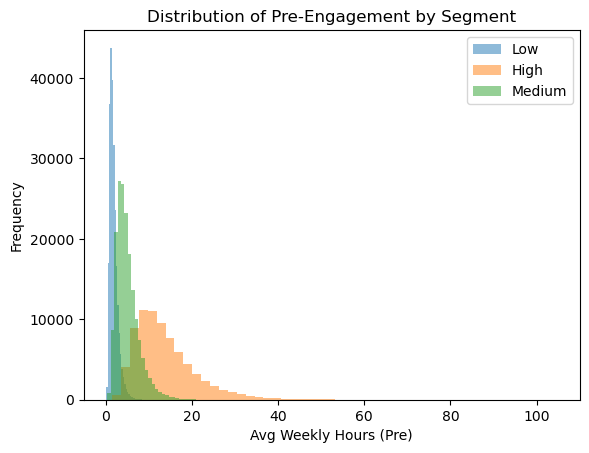

In [7]:
for segment in cust_df['segment'].unique():
    subset = cust_df[cust_df['segment'] == segment]
    plt.hist(subset['avg_weekly_hours_pre'], bins=50, alpha=0.5, label=segment)

plt.xlabel('Avg Weekly Hours (Pre)')
plt.ylabel('Frequency')
plt.title('Distribution of Pre-Engagement by Segment')
plt.legend()
plt.show()

### Responses File `responses.csv`

In [8]:
resp_df = pd.read_csv('../data/raw/responses.csv')
resp_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 5 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   customer_id         500000 non-null  int64  
 1   segment             500000 non-null  object 
 2   offer               500000 non-null  object 
 3   resubscribed_promo  500000 non-null  int64  
 4   resub_day           83656 non-null   float64
dtypes: float64(1), int64(2), object(2)
memory usage: 19.1+ MB


In [9]:
resp_df['segment'].value_counts(normalize=True)

segment
Low       0.499110
Medium    0.350796
High      0.150094
Name: proportion, dtype: float64

In [10]:
resp_df['offer'].value_counts(normalize=True)

offer
Free Trial      0.300002
Early Access    0.300002
Discount        0.300000
Control         0.099996
Name: proportion, dtype: float64

In [11]:
pd.crosstab(resp_df['segment'], resp_df['offer'], normalize='index')

offer,Control,Discount,Early Access,Free Trial
segment,,,,
High,0.100537,0.299386,0.300132,0.299945
Low,0.099249,0.300383,0.299966,0.300403
Medium,0.100828,0.299718,0.299998,0.299456


In [12]:
resp_df.groupby('offer')['resubscribed_promo'].mean()

offer
Control         0.072183
Discount        0.181427
Early Access    0.162872
Free Trial      0.189345
Name: resubscribed_promo, dtype: float64

In [13]:
resp_df.groupby('segment')['resubscribed_promo'].mean()

segment
High      0.239143
Low       0.162193
Medium    0.143861
Name: resubscribed_promo, dtype: float64

In [14]:
pivot = pd.pivot_table(
    resp_df,
    values='resubscribed_promo',
    index='segment',
    columns='offer',
    aggfunc='mean'
)

print(pivot)

offer     Control  Discount  Early Access  Free Trial
segment                                              
High     0.098741  0.220447      0.299192    0.244780
Low      0.059230  0.171167      0.150966    0.198447
Medium   0.078993  0.179380      0.121458    0.152597


In [15]:
control_rates = pivot['Control']

lift = pivot.subtract(control_rates, axis=0)
print(lift)

offer    Control  Discount  Early Access  Free Trial
segment                                             
High         0.0  0.121706      0.200451    0.146039
Low          0.0  0.111937      0.091736    0.139218
Medium       0.0  0.100386      0.042465    0.073603


Initial inspection of conversion rates against the control baseline reveals that incremental lift varies substantially by segment. Early Access drives a 20pp lift for High segment customers but only 4pp for Medium — suggesting the offer has highly heterogeneous effects across engagement levels. This motivates the segmented analysis in the next notebook.

In [16]:
converted = resp_df[resp_df['resubscribed_promo'] == 1]

converted.groupby('offer')['resub_day'].mean()

offer
Control         20.170684
Discount        19.898508
Early Access    19.944620
Free Trial      19.770192
Name: resub_day, dtype: float64

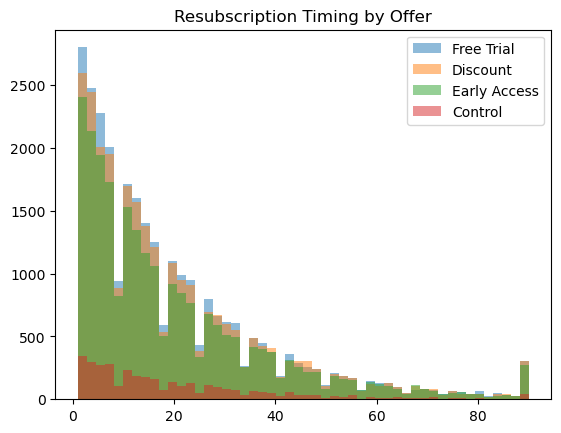

In [17]:
for offer in resp_df['offer'].unique():
    subset = converted[converted['offer'] == offer]
    plt.hist(subset['resub_day'], bins=50, alpha=0.5, label=offer)

plt.legend()
plt.title("Resubscription Timing by Offer")
plt.show()

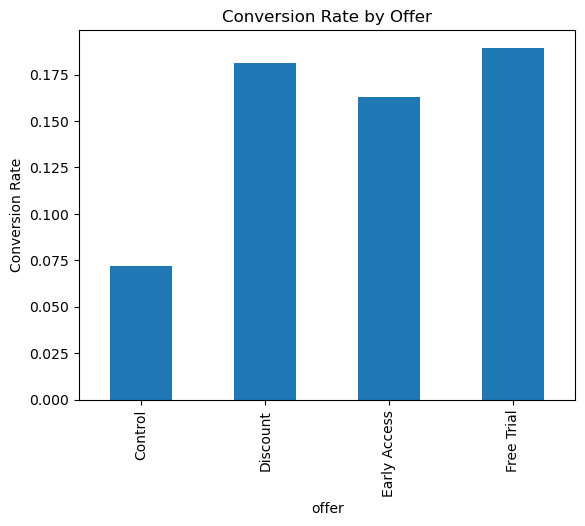

In [18]:
resp_df.groupby('offer')['resubscribed_promo'].mean().plot(kind='bar')

plt.title('Conversion Rate by Offer')
plt.ylabel('Conversion Rate')
plt.show()

### Views Table `views.csv`

In [19]:
views = pd.read_csv('../data/raw/views.csv')
views.sample(5)

,customer_id,day,hours_watched
125209,27546,39,2.394110
1098601,238114,57,1.434558
529903,116398,25,6.453580
43022,9514,66,1.387874
60731,13526,71,5.637501


In [20]:
views['customer_id'].nunique()

83656

In [21]:
views['day'].min(), views['day'].max()

(1, 90)

In [22]:
views['hours_watched'].describe()

count    2.308938e+06
mean     7.974664e+00
std      7.164247e+00
min      1.560675e-01
25%      2.675693e+00
50%      5.740210e+00
75%      1.117844e+01
max      1.169416e+02
Name: hours_watched, dtype: float64

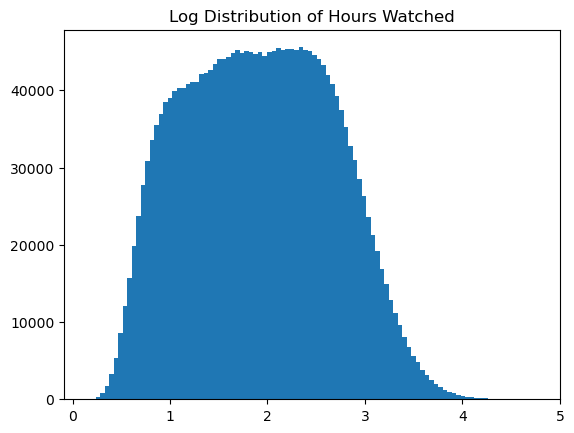

In [23]:
plt.hist(np.log1p(views['hours_watched']), bins=100)
plt.title("Log Distribution of Hours Watched")
plt.show()

In [24]:
user_engagement = views.groupby('customer_id').agg(
    total_hours=('hours_watched', 'sum'),
    active_days=('day', 'nunique'),
    avg_hours_per_day=('hours_watched', 'mean')
).reset_index()

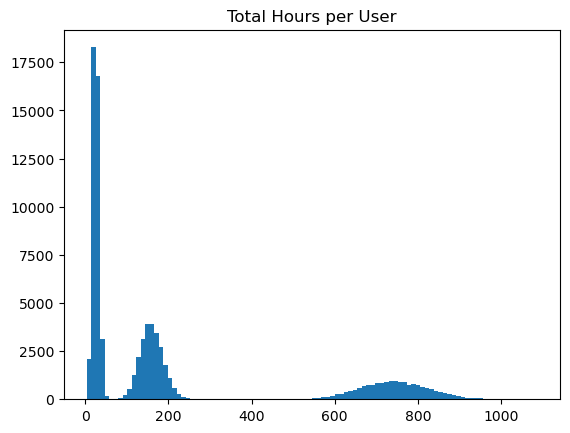

In [25]:
plt.hist(user_engagement['total_hours'], bins=100)
plt.title("Total Hours per User")
plt.show()

Customer segments show clearly separated distributions in both active days and total watch hours, reflecting the simulation parameters. In real data, overlap between segments would be greater

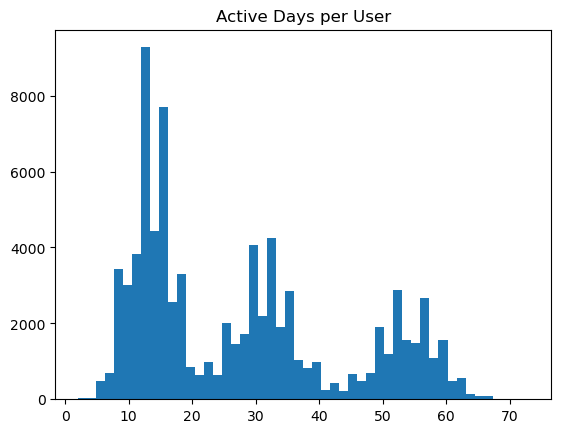

In [26]:
plt.hist(user_engagement['active_days'], bins=50)
plt.title("Active Days per User")
plt.show()

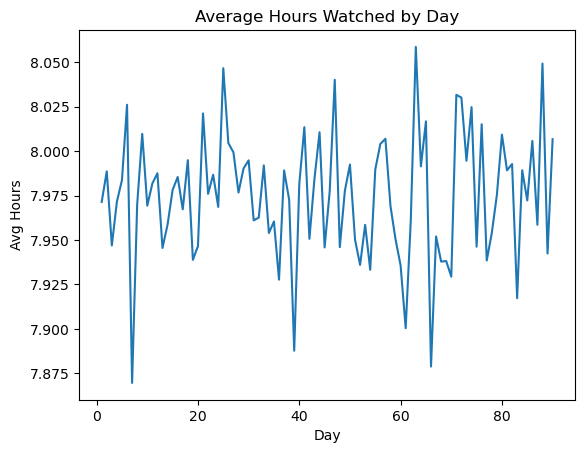

In [27]:
daily_trend = views.groupby('day')['hours_watched'].mean()

daily_trend.plot()
plt.title("Average Hours Watched by Day")
plt.xlabel("Day")
plt.ylabel("Avg Hours")
plt.show()

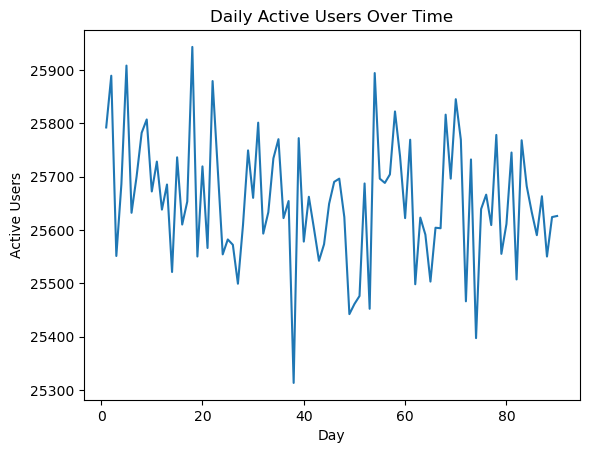

In [28]:
daily_active = views.groupby('day')['customer_id'].nunique()

daily_active.plot()
plt.title("Daily Active Users Over Time")
plt.xlabel("Day")
plt.ylabel("Active Users")
plt.show()

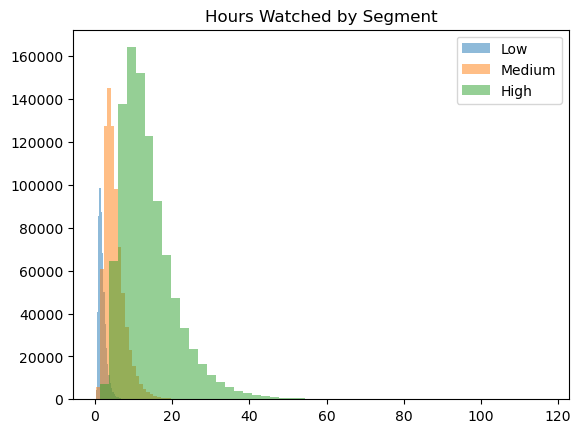

In [29]:
merged = views.merge(cust_df[['customer_id', 'segment', 'offer']], on='customer_id')
for seg in ['Low', 'Medium', 'High']:
    subset = merged[merged['segment'] == seg]
    plt.hist(subset['hours_watched'], bins=50, alpha=0.5, label=seg)

plt.legend()
plt.title("Hours Watched by Segment")
plt.show()

In [30]:
merged.groupby('offer')['hours_watched'].mean()

offer
Control         7.828142
Discount        7.484237
Early Access    8.822515
Free Trial      7.666163
Name: hours_watched, dtype: float64

In [31]:
pivot = pd.pivot_table(
    merged,
    values='hours_watched',
    index='segment',
    columns='offer',
    aggfunc='mean'
)

print(pivot)

offer      Control   Discount  Early Access  Free Trial
segment                                                
High     13.790004  13.791225     13.814888   13.778801
Low       1.867681   1.868350      1.864110    1.871917
Medium    5.085943   5.087471      5.076253    5.069395


In [32]:
conversion = resp_df.groupby('offer')['resubscribed_promo'].mean()
engagement = merged.groupby('offer')['hours_watched'].mean()

comparison = pd.DataFrame({
    'conversion_rate': conversion,
    'avg_hours': engagement
})

print(comparison)

              conversion_rate  avg_hours
offer                                   
Control              0.072183   7.828142
Discount             0.181427   7.484237
Early Access         0.162872   8.822515
Free Trial           0.189345   7.666163


In [33]:
conversion = resp_df.groupby('segment')['resubscribed_promo'].mean()
engagement = merged.groupby('segment')['hours_watched'].mean()

comparison = pd.DataFrame({
    'conversion_rate': conversion,
    'avg_hours': engagement
})

print(comparison)

         conversion_rate  avg_hours
segment                            
High            0.239143  13.796250
Low             0.162193   1.868449
Medium          0.143861   5.078813
